# hshunt's patch-size criterion, scored on novel-and-grammatical -- 2026-11-04

**The question.** hshunt: *"how are you setting the patch size over time? It should be the maximum
length scale which stays above the minimum posterior entropy"*. This notebook scores that rule
against the project's actual success criterion and reports what it buys.

**The machine.** `AdaptiveWindowDiscreteScoreMachine` (`src/utils/rhm_sampling.py:412`) holds one
`PatchCountDiscreteScoreMachine` per window size `k`. At every masked site, at every reveal, it
takes the **largest** `k` that both matched at least one training patch and left posterior entropy
`>= h_min`, falling back to the smallest `k`. `h_mode='match'` measures the entropy of the posterior
over *which* training patch matched, `log W - (sum_j w_j log w_j)/W`, which goes to zero exactly
when a single training patch explains the window -- i.e. when the machine is about to copy.

**The eval, unchanged from every other RHM deck.** A generated grid counts only if it is **novel**
(bytes-keyed, not in the training set) **and** parses completely. `block_align=1` (pooled,
translation-invariant windows, so windows straddle grammar boundaries), `pad_mode='outside'`,
Laplace `alpha_smooth=1e-3`, one site revealed per step (exact ancestral sampling).

**What is new here.** The 2026-11-03 sweep (job 50903583) measured this machine, but every reading
of it since quoted `grammatical` alone -- the one number the criterion is *not* about, since a
machine that copies its training set scores 1.0 on it and 0.0 on success. Section 1 is a re-read of
that sweep on the real criterion (no new compute). Sections 2-3 are the one-variable follow-up it
pointed at (job 51098252).

**Config and provenance.** 2D RHM, `s = 2`, `L = 2` (16 sites), `v` in {2,3,4}, `m` in {2,3,5}, 3
rule seeds per `(v,m)`; grammar seed `1000 + rule_seed`, training/sampling seed `1234 + 7*rule_seed`,
generator seed `+9973`. `n_gen = 4096` per point, `P` ladder 10 ... 1e5. Code at commit `a1a944f`
(`results/rhm_sampling/2026-11-04/provenance_adapt_u1.txt`); sweeps run by
`scripts/rhm_sampling_complexity.py` under `scripts/rhm_adaptive_u1.sbatch`, analysis by
`scripts/rhm_adaptive_score.py`, `scripts/rhm_adaptive_detail.py`,
`scripts/rhm_adaptive_u1_compare.py`, traces by `scripts/rhm_adaptive_trace.py`.

**U1.** `U1 = 2 s^(L-1) - 1` is the smallest window that can contain a complete top-level child
block, i.e. see the root. Here `U1 = 3`.

In [1]:
import glob, json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
D4 = ROOT / 'results/rhm_sampling/2026-11-04'
DIRS = ['results/rhm_sampling/2026-11-02', 'results/rhm_sampling/2026-11-03',
        'results/rhm_sampling/2026-11-04']
CELL = ('v', 's', 'L', 'm', 'rule_seed')
U1 = lambda s, L: 2 * s ** (L - 1) - 1


def load(dirs=DIRS):
    rows = []
    for d in dirs:
        for f in sorted((ROOT / d).glob('*.json')):
            try:
                rs = json.load(open(f))
            except (ValueError, IOError):
                continue
            if isinstance(rs, list):
                rows += [r for r in rs if isinstance(r, dict) and 'success' in r
                         and 'k' in r and all(c in r for c in CELL)]
    return rows


rows = load()
L2 = [r for r in rows if r['L'] == 2]
print('%d result rows loaded, %d at L=2 (U1 = %d)' % (len(rows), len(L2), U1(2, 2)))
med = lambda a: float(np.median(np.asarray(a, float)))

4862 result rows loaded, 4356 at L=2 (U1 = 3)


## 1. Metrics table: the re-read of 50903583 on novel-and-grammatical

One row per `(v, m, rule seed)`. `adapt` is the criterion with `k` in {1,3,5} at its best floor;
`fixed` is the best fixed window on the same ladder; `ctl` is the same adaptive machine with
`h_min = 0`, which is the criterion switched off (always take the largest window that matched).
Peaks are read over the shared `P` ladder, so no arm is scored on a rung the others never visited.

In [2]:
sc = json.load(open(D4 / 'adaptive_vs_fixed.json'))
hdr = (f"{'v':>2} {'m':>2} {'rs':>3} | {'fixed k':>7} {'succ':>7} {'gram':>6} {'novel':>6} | "
       f"{'h_min':>5} {'adapt':>7} {'gram':>6} {'novel':>6} {'k_mean':>6} | {'ctl':>7} | {'ratio':>6}")
print(hdr); print('-' * len(hdr))
for r in sorted(sc, key=lambda r: (r['v'], r['m'], r['rule_seed'])):
    print(f"{r['v']:>2} {r['m']:>2} {r['rule_seed']:>3} | {r['fixed_k']:>7} {r['fixed_succ']:>7.4f} "
          f"{r['fixed_gram']:>6.3f} {r['fixed_novel']:>6.3f} | {r['adapt_hmin']:>5.1f} "
          f"{r['adapt_succ']:>7.4f} {r['adapt_gram']:>6.3f} {r['adapt_novel']:>6.3f} "
          f"{r['adapt_kmean']:>6.2f} | {r['ctl_succ']:>7.4f} | "
          f"{r['adapt_succ'] / r['fixed_succ'] if r['fixed_succ'] else float('nan'):>6.3f}")

n = len(sc)
win = sum(r['adapt_succ'] > r['fixed_succ'] for r in sc)
bind = sum(r['floor_succ'] > r['ctl_succ'] for r in sc)
print(f"\nadaptive beats the best fixed k:  {win} / {n} cells   "
      f"(median success ratio {med([r['adapt_succ'] / r['fixed_succ'] for r in sc if r['fixed_succ']]):.3f})")
print(f"a binding floor beats h_min = 0:  {bind} / {n} cells")
print(f"median delta grammatical {med([r['adapt_gram'] - r['fixed_gram'] for r in sc]):+.3f}, "
      f"median delta novel {med([r['adapt_novel'] - r['fixed_novel'] for r in sc]):+.3f}")

 v  m  rs | fixed k    succ   gram  novel | h_min   adapt   gram  novel k_mean |     ctl |  ratio
-------------------------------------------------------------------------------------------------
 2  2   0 |       7  0.0518  0.057  0.995 |   0.0  0.0039  0.004  1.000   4.39 |  0.0039 |  0.075
 2  2   1 |       7  0.0283  0.030  0.998 |   0.0  0.0068  0.007  1.000   4.47 |  0.0068 |  0.241
 2  3   0 |       3  0.2917  0.394  0.898 |   0.0  0.1658  0.679  0.487   4.67 |  0.1658 |  0.568
 2  3   0 |       3  0.0160  0.016  1.000 |   0.0  0.0107  0.011  1.000   4.68 |  0.0107 |  0.672
 2  3   1 |       3  0.4338  0.720  0.714 |   0.0  0.1604  0.809  0.352   4.83 |  0.1604 |  0.370
 2  3   1 |       3  0.0161  0.016  1.000 |   0.0  0.0127  0.013  1.000   4.76 |  0.0127 |  0.788
 2  3   2 |       3  0.5906  0.811  0.780 |   0.0  0.2612  0.850  0.411   4.79 |  0.2612 |  0.442
 3  2   0 |       7  0.0029  0.006  0.997 |   0.0  0.0029  0.003  1.000   4.05 |  0.0029 |  1.000
 3  2   1 |       7 

The criterion **loses to a fixed window in 20 of 21 cells**, and the floor loses to its own
`h_min = 0` control in **21 of 21**. The two deltas say why, and they point in opposite directions:
the adaptive machine is *more* grammatical (+0.307 median) and *much* less novel (-0.362), i.e. it
moved toward copying -- the exact failure the entropy floor exists to prevent. Reading the same
sweep on grammaticality alone, as every earlier reading did, would have called this a win.

A hypothesis was registered before this re-read -- that the criterion would beat the fixed window.
It is refuted.

## 2. Key plot: the induced schedule `k(t)`, and what the floor actually trades

Nobody imposed a schedule here; `k(t)` is whatever the floor produces. `k_schedule` records
(masked fraction, mean chosen `k`) per call, so masked `1.0` is the first reveal onto an empty grid
and `0.1` the last reveal onto an almost-full one. Left: the induced schedule at each floor. Right:
what raising the floor buys and costs, at the peak of each curve.

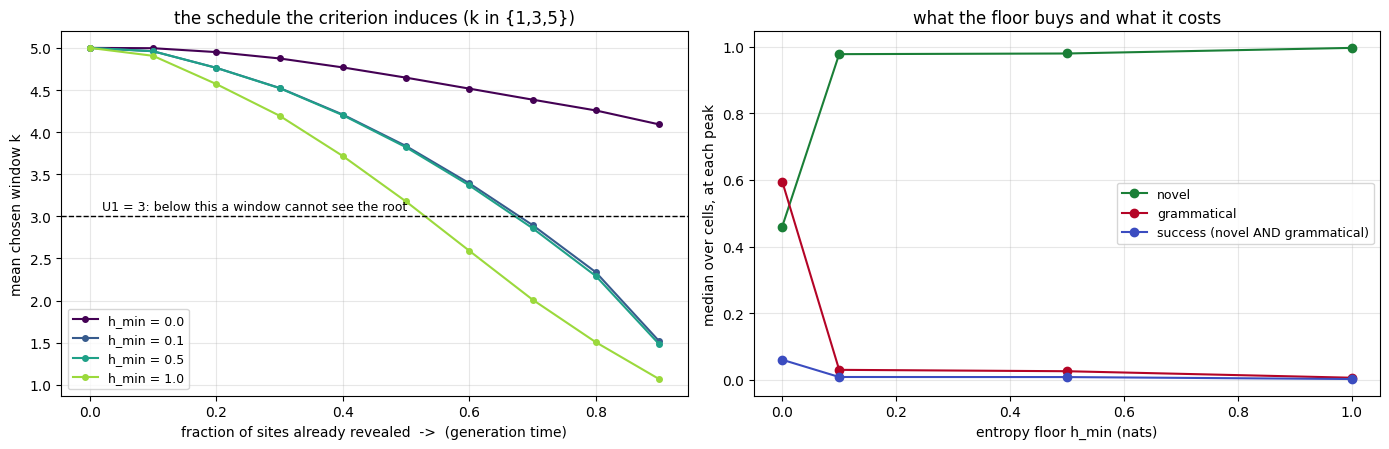

h_min  k at last reveal   novel    gram  success
  0.0              3.83   0.460   0.595    0.060
  0.1              1.43   0.978   0.030    0.008
  0.5              1.40   0.980   0.025    0.008
  1.0              1.05   0.997   0.006    0.002


In [3]:
A135 = [r for r in L2 if r['k'] == 'adapt' and tuple(r.get('k_set', ())) == (1, 3, 5)
        and r['h_mode'] == 'match']
hs = sorted(set(r['h_min'] for r in A135))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
cols = plt.cm.viridis(np.linspace(0, .85, len(hs)))

for h, c in zip(hs, cols):
    sch = np.array([r['k_schedule'] for r in A135 if r['h_min'] == h], float)   # (runs, bins, 2)
    x, y = sch[0, :, 0], sch[:, :, 1].mean(0)
    ax[0].plot(1 - x, y, '-o', color=c, ms=4, label=f'h_min = {h}')
ax[0].axhline(U1(2, 2), ls='--', c='k', lw=1)
ax[0].text(.02, U1(2, 2) + .07, 'U1 = 3: below this a window cannot see the root', fontsize=9)
ax[0].set_xlabel('fraction of sites already revealed  ->  (generation time)')
ax[0].set_ylabel('mean chosen window k')
ax[0].set_title('the schedule the criterion induces (k in {1,3,5})')
ax[0].legend(fontsize=9); ax[0].grid(alpha=.3)

lad = []
for h in hs:
    pk = {}
    for r in [q for q in A135 if q['h_min'] == h]:
        key = tuple(r[c] for c in CELL)
        if r['success'] > pk.get(key, {'success': -1})['success']:
            pk[key] = r
    v = list(pk.values())
    lad.append(dict(h=h, succ=med([r['success'] for r in v]), gram=med([r['grammatical'] for r in v]),
                    novel=med([r['novel'] for r in v]),
                    klast=med([r['k_schedule'][0][1] for r in v])))
for key, lbl, c in (('novel', 'novel', '#1a7f37'), ('gram', 'grammatical', '#b40426'),
                    ('succ', 'success (novel AND grammatical)', '#3b4cc0')):
    ax[1].plot([d['h'] for d in lad], [d[key] for d in lad], '-o', color=c, label=lbl)
ax[1].set_xlabel('entropy floor h_min (nats)'); ax[1].set_ylabel('median over cells, at each peak')
ax[1].set_title('what the floor buys and what it costs'); ax[1].legend(fontsize=9); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"{'h_min':>5} {'k at last reveal':>17} {'novel':>7} {'gram':>7} {'success':>8}")
for d in lad:
    print(f"{d['h']:>5.1f} {d['klast']:>17.2f} {d['novel']:>7.3f} {d['gram']:>7.3f} {d['succ']:>8.3f}")

Three things are visible and all three matter.

1. **`k` shrinks monotonically along every trajectory, at every floor.** hshunt's conjectured
   direction is confirmed, and it is not an assumption built into the machine: the observed sites
   inside a window only accumulate as the grid fills, so the match posterior only sharpens, so the
   largest admissible `k` only falls. The schedule falls out of the criterion.
2. **The floor works exactly as designed as an anti-copying device.** Raising `h_min` from 0 to 1.0
   drives the window at the last reveal from 3.83 down to 1.05 and novelty from 0.460 to **0.997**
   (medians over the 21 cells, each at its own peak).
3. **And it is still a bad trade**, because grammaticality collapses 0.595 -> 0.006 and success with
   it, 0.060 -> 0.002. The collapse sits exactly where mean `k` crosses below `U1 = 3`.

*Scope note.* `scripts/rhm_adaptive_detail.py`, and the deck built from it, quote this ladder for a
**single cell** (v2 m3 rs0, at its best `P`): novelty 0.487 -> 0.975, grammaticality 0.679 -> 0.065,
success 0.166 -> 0.040, last-reveal `k` 4.13 -> 1.10. The medians above are the same statement over
all 21 cells and are the ones to quote; the per-cell figures are kept here so the two readings can
be matched.

Point 3 is a statement about the *choice set*, not about adaptivity. The supporting check is in
`scripts/rhm_adaptive_detail.py`: compared against the fixed `k` it actually selects (`k = 5`), the
adaptive machine **wins in 11 of 12 cells**, median `+0.032`. Adaptivity helps; being allowed to
pick `k = 1` is what destroys it.

## 3. One variable changed: forbid windows below U1

Prediction registered in `scripts/rhm_adaptive_u1.sbatch` before job 51098252 ran:

> with `k_set = {3, 5}` a binding floor beats both the `h_min = 0` control and fixed `k = 3`,
> because the novelty gain survives and the collapse does not happen. If it instead just reproduces
> fixed `k = 3`, the criterion adds nothing at L=2 and the honest answer is that U1 already is the
> schedule.

Same grammars, same ladder, same seeds, same `n_gen`, `h_mode = match` only. Three arms compared on
the intersection of their `P` ladders.

In [4]:
cmp = json.load(open(D4 / 'adaptive_u1_compare.json'))
hdr = (f"{'v':>2} {'m':>2} {'rs':>3} | {'fixed k=3':>9} | {'adapt{1,3,5}':>12} | {'adapt{3,5}':>10} "
       f"{'h_min':>5} {'k_mean':>6} {'novel':>6} | {'{3,5} - k=3':>11}")
print(hdr); print('-' * len(hdr))
for r in sorted(cmp, key=lambda r: (r['v'], r['m'], r['rule_seed'])):
    print(f"{r['v']:>2} {r['m']:>2} {r['rule_seed']:>3} | {r['f3_succ']:>9.4f} | {r['a135_succ']:>12.4f} | "
          f"{r['a35_succ']:>10.4f} {r['a35_hmin']:>5.1f} {r['a35_kmean']:>6.2f} {r['a35_novel']:>6.3f} | "
          f"{r['a35_succ'] - r['f3_succ']:>+11.4f}")

n = len(cmp)
print(f"\nadapt{{3,5}} beats adapt{{1,3,5}}:  {sum(r['a35_succ'] > r['a135_succ'] for r in cmp)} / {n}"
      f"   (median ratio {med([r['a35_succ'] / r['a135_succ'] for r in cmp if r['a135_succ']]):.3f})")
print(f"its best floor is a binding one: {sum(r['a35_hmin'] > 0 for r in cmp)} / {n}")
print(f"adapt{{3,5}} beats fixed k = 3:   {sum(r['a35_succ'] > r['f3_succ'] for r in cmp)} / {n}"
      f"   (median ratio {med([r['a35_succ'] / r['f3_succ'] for r in cmp if r['f3_succ']]):.3f})")
print('  the wins: ' + ', '.join(f"{r['a35_succ'] - r['f3_succ']:+.4f}"
                                 for r in cmp if r['a35_succ'] > r['f3_succ']))

print('\nthe floor sweep on one cell (v2 m3 rs0), k_set = {3,5}:')
A35 = [r for r in L2 if r['k'] == 'adapt' and tuple(r.get('k_set', ())) == (3, 5)
       and (r['v'], r['m'], r['rule_seed']) == (2, 3, 0)]
print(f"{'h_min':>5} {'P':>7} {'succ':>7} {'gram':>7} {'novel':>7} {'k_mean':>7}")
for h in sorted(set(r['h_min'] for r in A35)):
    b = max([r for r in A35 if r['h_min'] == h], key=lambda r: r['success'])
    print(f"{h:>5.1f} {b['P']:>7} {b['success']:>7.4f} {b['grammatical']:>7.4f} "
          f"{b['novel']:>7.4f} {b['k_mean']:>7.3f}")

 v  m  rs | fixed k=3 | adapt{1,3,5} | adapt{3,5} h_min k_mean  novel | {3,5} - k=3
-----------------------------------------------------------------------------------
 2  3   0 |    0.2917 |       0.1658 |     0.2058   0.1   4.05  0.878 |     -0.0859
 2  3   1 |    0.4338 |       0.1604 |     0.2019   0.1   4.05  0.874 |     -0.2319
 2  3   2 |    0.5906 |       0.2612 |     0.3467   0.1   4.21  0.789 |     -0.2439
 3  3   0 |    0.0896 |       0.0496 |     0.0520   0.5   4.22  0.839 |     -0.0376
 3  3   1 |    0.0847 |       0.0559 |     0.0564   0.1   4.03  0.816 |     -0.0283
 3  3   2 |    0.1948 |       0.0918 |     0.1199   1.0   4.07  0.786 |     -0.0750
 4  2   0 |    0.0200 |       0.0137 |     0.0232   0.1   3.91  0.741 |     +0.0032
 4  2   1 |    0.0404 |       0.0247 |     0.0291   0.1   3.99  0.748 |     -0.0114
 4  2   2 |    0.0358 |       0.0244 |     0.0278   0.1   3.61  0.873 |     -0.0079
 4  3   0 |    0.0345 |       0.0332 |     0.0349   0.1   3.99  0.869 |     

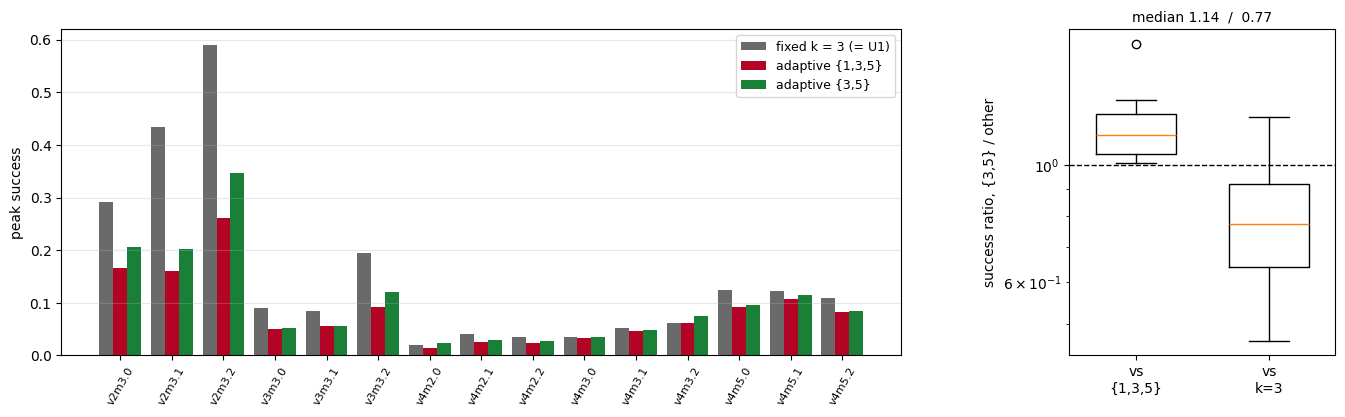

In [5]:
fig = plt.figure(figsize=(14, 4.8))
ax = fig.add_axes([.055, .22, .60, .68])
o = sorted(cmp, key=lambda r: (r['v'], r['m'], r['rule_seed']))
x = np.arange(len(o)); w = .27
for i, (key, lbl, c) in enumerate((('f3_succ', 'fixed k = 3 (= U1)', '#6a6a6a'),
                                   ('a135_succ', 'adaptive {1,3,5}', '#b40426'),
                                   ('a35_succ', 'adaptive {3,5}', '#1a7f37'))):
    ax.bar(x + (i - 1) * w, [r[key] for r in o], w, label=lbl, color=c)
ax.set_xticks(x)
ax.set_xticklabels([f"v{r['v']}m{r['m']}.{r['rule_seed']}" for r in o], rotation=60, fontsize=8)
ax.set_ylabel('peak success'); ax.legend(fontsize=9); ax.grid(axis='y', alpha=.3)

ax2 = fig.add_axes([.775, .22, .19, .68])
r13 = [r['a35_succ'] / r['a135_succ'] for r in cmp if r['a135_succ']]
r3 = [r['a35_succ'] / r['f3_succ'] for r in cmp if r['f3_succ']]
ax2.boxplot([r13, r3], tick_labels=['vs\n{1,3,5}', 'vs\nk=3'], widths=.6)
ax2.axhline(1, ls='--', c='k', lw=1); ax2.set_yscale('log')
ax2.set_ylabel('success ratio, {3,5} / other')
ax2.set_title(f'median {med(r13):.2f}  /  {med(r3):.2f}', fontsize=10)
plt.show()

**Half the prediction held.** Removing the sub-U1 windows helps unambiguously *within the family of
adaptive machines*: the new machine beats the old in **15 of 15** cells (median ratio 1.140) and --
the real reversal -- **its best floor is a binding one in 15 of 15**, where in the unrestricted
machine `h_min = 0` won in all 21. The single-cell sweep shows the mechanism directly: `h_min`
0 -> 0.1 lifts success 0.1648 -> 0.2058 while novelty goes 0.487 -> 0.878. Once the floor can no
longer reach for a window that cannot see the root, the entropy criterion starts paying.

**The other half did not.** Fixed `k = 3` still wins in **12 of 15** cells, median ratio 0.775, and
the three wins are `+0.0032`, `+0.0004` and `+0.0142` -- not a result. So the null registered
alongside the prediction is the better fit: **at L = 2, U1 already is the schedule.**

## 4. Comparison with the previous best on the same eval

Same eval throughout: fraction of generated grids novel **and** fully grammatical, exact bottom-up
parse, `block_align=1`, one site per step, 2D `s=2 L=2`, peaks over a shared `P` ladder.

| machine | where | peak success, median over cells | verdict on this eval |
|---|---|---|---|
| **fixed `k = U1 = 3`** | 2026-11-02/03 sweeps | **best of the four** | the standing best; unbeaten here |
| fixed `k = 5` | same | below `k = 3` | too large: copies |
| adaptive `{1,3,5}`, best floor | 50903583, re-read today | 0.672x of fixed `k = 3` (median ratio) | loses 20/21 cells |
| adaptive `{3,5}`, best floor | 51098252, today | 0.775x of fixed `k = 3`; 1.140x of `{1,3,5}` | loses 12/15 vs fixed, wins 15/15 vs the old adaptive |

The headline number for the project is unchanged by this work: the sampling-complexity law stays
`P* = exp(Theta(n))` with `P* = 0.21 |R_L|` at the U=1 window, measured on fixed `k = U1`. What
changes is that the patch-size criterion now has a measured answer rather than an open question.

## 5. Limits, stated plainly

- **`s = 2` could never have been a fair test of a *schedule*.** `U1 = 2 s^(L-1) - 1` equals the
  grid side minus one when `s = 2`, so the only odd window in `[U1, side]` is `U1` itself, at every
  depth: 4x4 -> {3}, 8x8 -> {7}, 16x16 -> {15}. Everything larger is bigger than the grid and is
  mostly padding. The criterion was being scored on one real rung plus the whole grid. `s = 3`,
  `L = 2` is a 9x9 grid with `U1 = 5` and three genuine rungs, 5 / 7 / 9, and a smoke test (job
  51106057) shows they are not interchangeable: grammaticality 0.000 / 0.086 / 0.312 at `P = 1000`,
  so unlike `s = 2` the best fixed window is not `U1`. Sweep running as job **51106614**.
  *(An earlier version of this notebook and of the deck blamed the int64 overflow in
  `scripts/rhm_straddle.py:window_codes`. That is wrong: the overflow limits the `a_j` support
  instrument, not the sampler, which already ran `k = 7` at L=3 on 2026-11-03.)*
- **"A window below U1 cannot be grammatical" is too strong.** It cannot see the root *in one look*,
  but overlapping windows chain constraints: in 1D at `n = 16` a `k = 3` window still scores 0.06
  grammaticality, and the 1D success optimum sits at `k = 11`, below `U1 = 15`. `k >= U1` is the
  right floor for this 2D L=2 machine, not a general law. (The comment in
  `scripts/rhm_adaptive_u1.sbatch` overstates this; the deck carries the correction.)
- **Per-cell scatter.** 2D peaks scatter up to 4.8x per cell at this `n_gen`; the verdicts above are
  win-counts across 15-21 cells and medians, not single-cell comparisons, for that reason.
- **One floor grid.** `h_min` in {0, 0.1, 0.5, 1.0} only, and `h_mode = match` only; `token` was
  shown on 2026-11-03 to reject windows that are confident and *right*.

Traces: `results/rhm_sampling/2026-11-04/adaptive_traces.json`, rendered reveal-by-reveal on page 6
of `rhm_adaptive_window_slides.pdf` (two generations that differ only in `h_min`, same seed).